In [25]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import StandardScaler , MinMaxScaler
from sklearn.metrics import silhouette_score
from sklearn.datasets import make_moons
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import adjusted_rand_score

In [2]:
df = pd.read_csv("Mall_Customers.csv")

In [3]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [6]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [7]:
features = ["Annual Income (k$)", "Spending Score (1-100)"]
X = df[features]

In [8]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [9]:
X_scaled_df = pd.DataFrame(X_scaled, columns=features)
print(X_scaled_df.describe().round(2))

       Annual Income (k$)  Spending Score (1-100)
count              200.00                  200.00
mean                -0.00                   -0.00
std                  1.00                    1.00
min                 -1.74                   -1.91
25%                 -0.73                   -0.60
50%                  0.04                   -0.01
75%                  0.67                    0.89
max                  2.92                    1.89


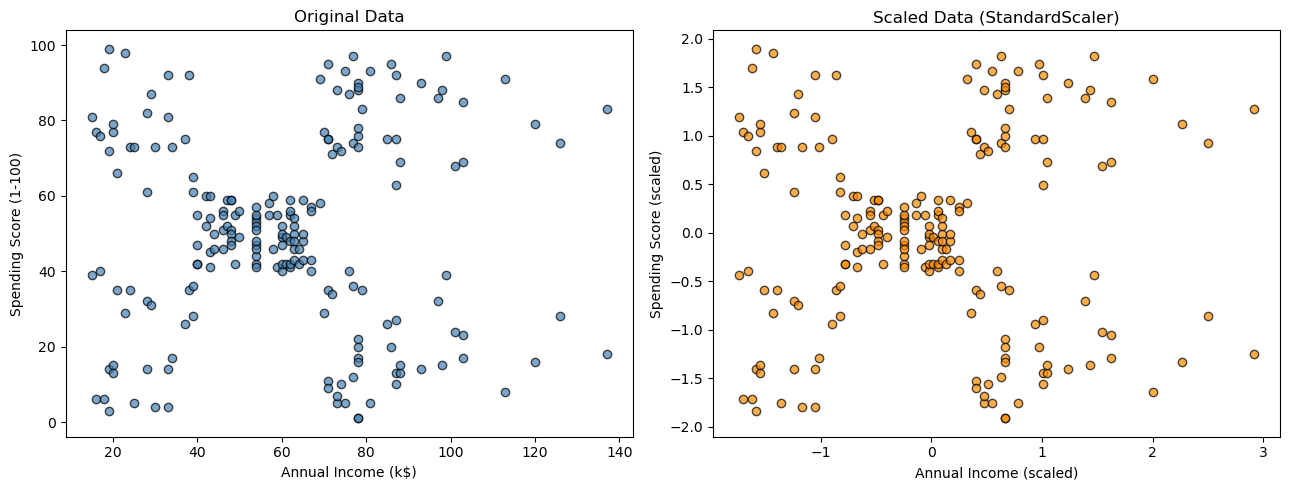

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(X[features[0]], X[features[1]], color="steelblue", edgecolor="k", alpha=0.7)
axes[0].set_title("Original Data")
axes[0].set_xlabel("Annual Income (k$)")
axes[0].set_ylabel("Spending Score (1-100)")
axes[1].scatter(X_scaled_df[features[0]], X_scaled_df[features[1]], color="darkorange", edgecolor="k", alpha=0.7)
axes[1].set_title("Scaled Data (StandardScaler)")
axes[1].set_xlabel("Annual Income (scaled)")
axes[1].set_ylabel("Spending Score (scaled)")
plt.tight_layout()
plt.show()

In [ ]:
k_range = range(2, 11)
wcss = []
sil_scores = []

for k in k_range:
    kmeans = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    labels = kmeans.fit_predict(X_scaled)
    wcss.append(kmeans.inertia_)                      # WCSS
    sil_scores.append(silhouette_score(X_scaled, labels))

for k, w, s in zip(k_range, wcss, sil_scores):
    print(f"K={k}  WCSS={w:.2f}  Silhouette={s:.4f}")

K=2  WCSS=269.69  Silhouette=0.3213
K=3  WCSS=157.70  Silhouette=0.4666
K=4  WCSS=108.92  Silhouette=0.4939
K=5  WCSS=65.57  Silhouette=0.5547
K=6  WCSS=55.06  Silhouette=0.5399
K=7  WCSS=44.86  Silhouette=0.5281
K=8  WCSS=37.23  Silhouette=0.4552
K=9  WCSS=32.39  Silhouette=0.4571
K=10  WCSS=29.98  Silhouette=0.4432


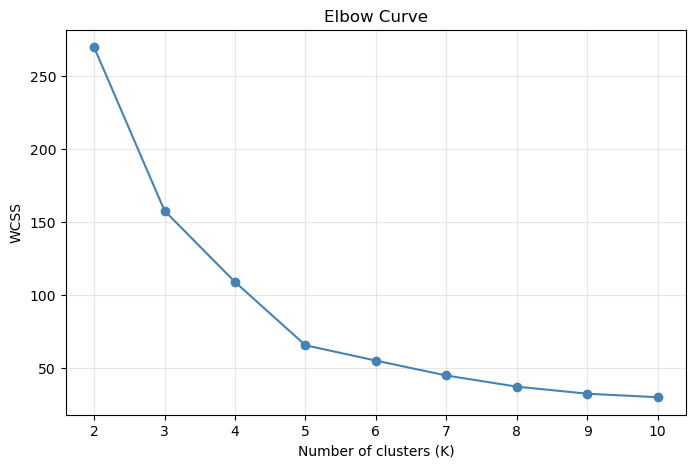

In [13]:
plt.figure(figsize=(8, 5))
plt.plot(k_range, wcss, marker="o", color="steelblue")
plt.title("Elbow Curve")
plt.xlabel("Number of clusters (K)")
plt.ylabel("WCSS")
plt.xticks(list(k_range))
plt.grid(alpha=0.3)
plt.show()

In [15]:
%pip install kneed

Note: you may need to restart the kernel to use updated packages.


In [16]:
from kneed import KneeLocator
kl = KneeLocator(list(k_range), wcss, curve="convex", direction="decreasing")
print("Elbow point (K) =", kl.elbow)

Elbow point (K) = 5


In [17]:
optimal_k = kl.elbow if kl.elbow else 5   # fallback لو الـ kneed ما لقاش elbow
kmeans_final = KMeans(n_clusters=optimal_k, init="k-means++", n_init=10, random_state=42)
final_labels = kmeans_final.fit_predict(X_scaled)
final_sil = silhouette_score(X_scaled, final_labels)
print(f"Chosen K = {optimal_k}  ->  Silhouette Score = {final_sil:.4f}")

Chosen K = 5  ->  Silhouette Score = 0.5547


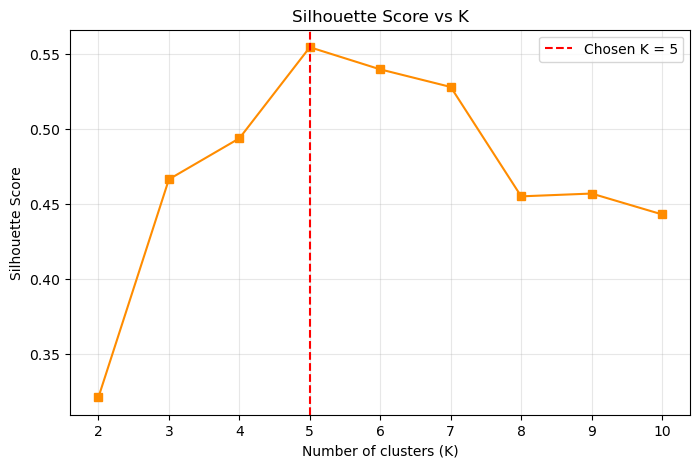

In [18]:
plt.figure(figsize=(8, 5))
plt.plot(k_range, sil_scores, marker="s", color="darkorange")
plt.axvline(optimal_k, color="red", linestyle="--", label=f"Chosen K = {optimal_k}")
plt.title("Silhouette Score vs K")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(list(k_range))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

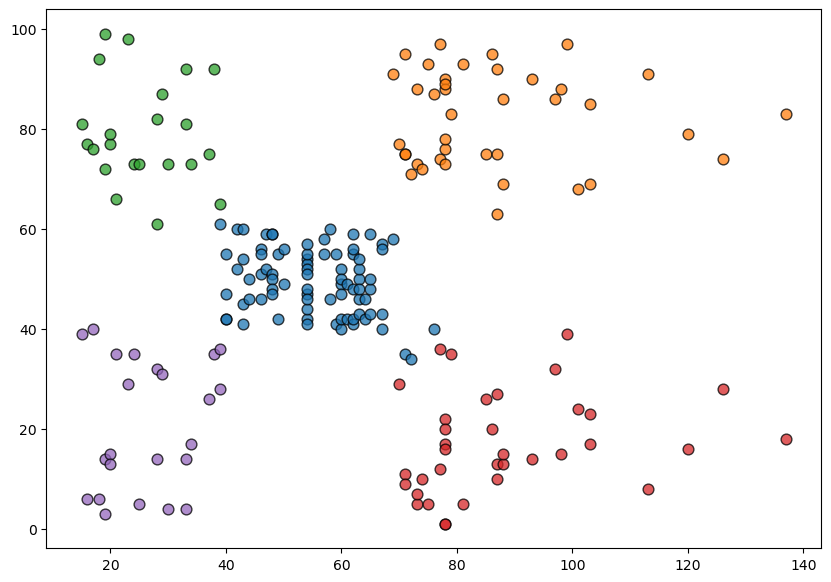

In [21]:
kmeans_final = KMeans(n_clusters=optimal_k, init="k-means++", n_init=10, random_state=42)
df["Cluster"] = kmeans_final.fit_predict(X_scaled)
centroids = scaler.inverse_transform(kmeans_final.cluster_centers_)
plt.figure(figsize=(10, 7))
colors = plt.cm.tab10.colors

for c in range(optimal_k):
    cluster_points = df[df["Cluster"] == c]
    plt.scatter(
        cluster_points["Annual Income (k$)"],
        cluster_points["Spending Score (1-100)"],
        s=60, color=colors[c], edgecolor="k", alpha=0.75,
        label=f"Cluster {c}"
    )

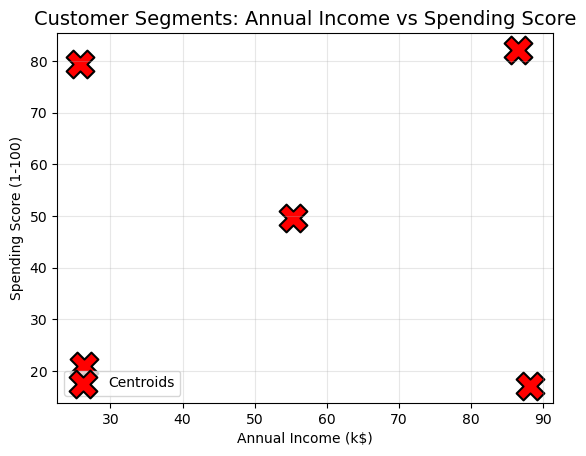

In [22]:
plt.scatter(
    centroids[:, 0], centroids[:, 1],
    s=400, marker="X", color="red", edgecolor="black", linewidth=1.5,
    label="Centroids"
)

plt.title("Customer Segments: Annual Income vs Spending Score", fontsize=14)
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [23]:
summary = df.groupby("Cluster").agg(
    Customers=("Cluster", "count"),
    Avg_Income=("Annual Income (k$)", "mean"),
    Avg_Spending=("Spending Score (1-100)", "mean")
).round(1)
print(summary)

         Customers  Avg_Income  Avg_Spending
Cluster                                     
0               81        55.3          49.5
1               39        86.5          82.1
2               22        25.7          79.4
3               35        88.2          17.1
4               23        26.3          20.9


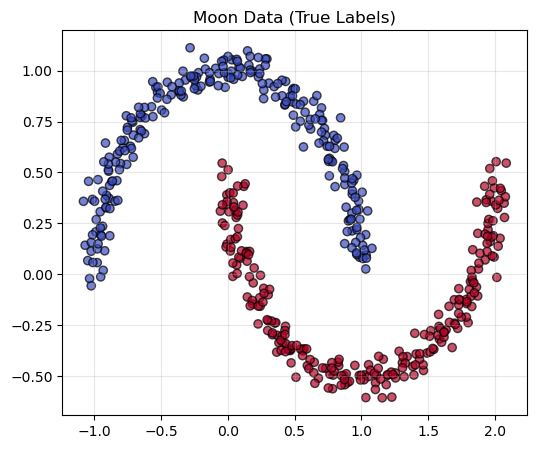

In [26]:
X_moons, y_true = make_moons(n_samples=500, noise=0.05, random_state=42)
plt.figure(figsize=(6, 5))
plt.scatter(X_moons[:, 0], X_moons[:, 1], c=y_true, cmap="coolwarm", edgecolor="k", alpha=0.7)
plt.title("Moon Data (True Labels)")
plt.grid(alpha=0.3)
plt.show()

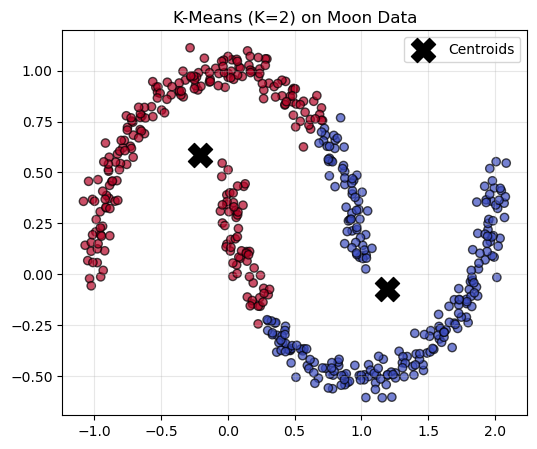

In [27]:
kmeans_moons = KMeans(n_clusters=2, n_init=10, random_state=42)
km_labels = kmeans_moons.fit_predict(X_moons)
plt.figure(figsize=(6, 5))
plt.scatter(X_moons[:, 0], X_moons[:, 1], c=km_labels, cmap="coolwarm", edgecolor="k", alpha=0.7)
plt.scatter(kmeans_moons.cluster_centers_[:, 0], kmeans_moons.cluster_centers_[:, 1],
            s=300, marker="X", color="black", label="Centroids")
plt.title("K-Means (K=2) on Moon Data")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [28]:
km_ari = adjusted_rand_score(y_true, km_labels)
print(f"K-Means  ARI = {km_ari:.3f}")

K-Means  ARI = 0.253


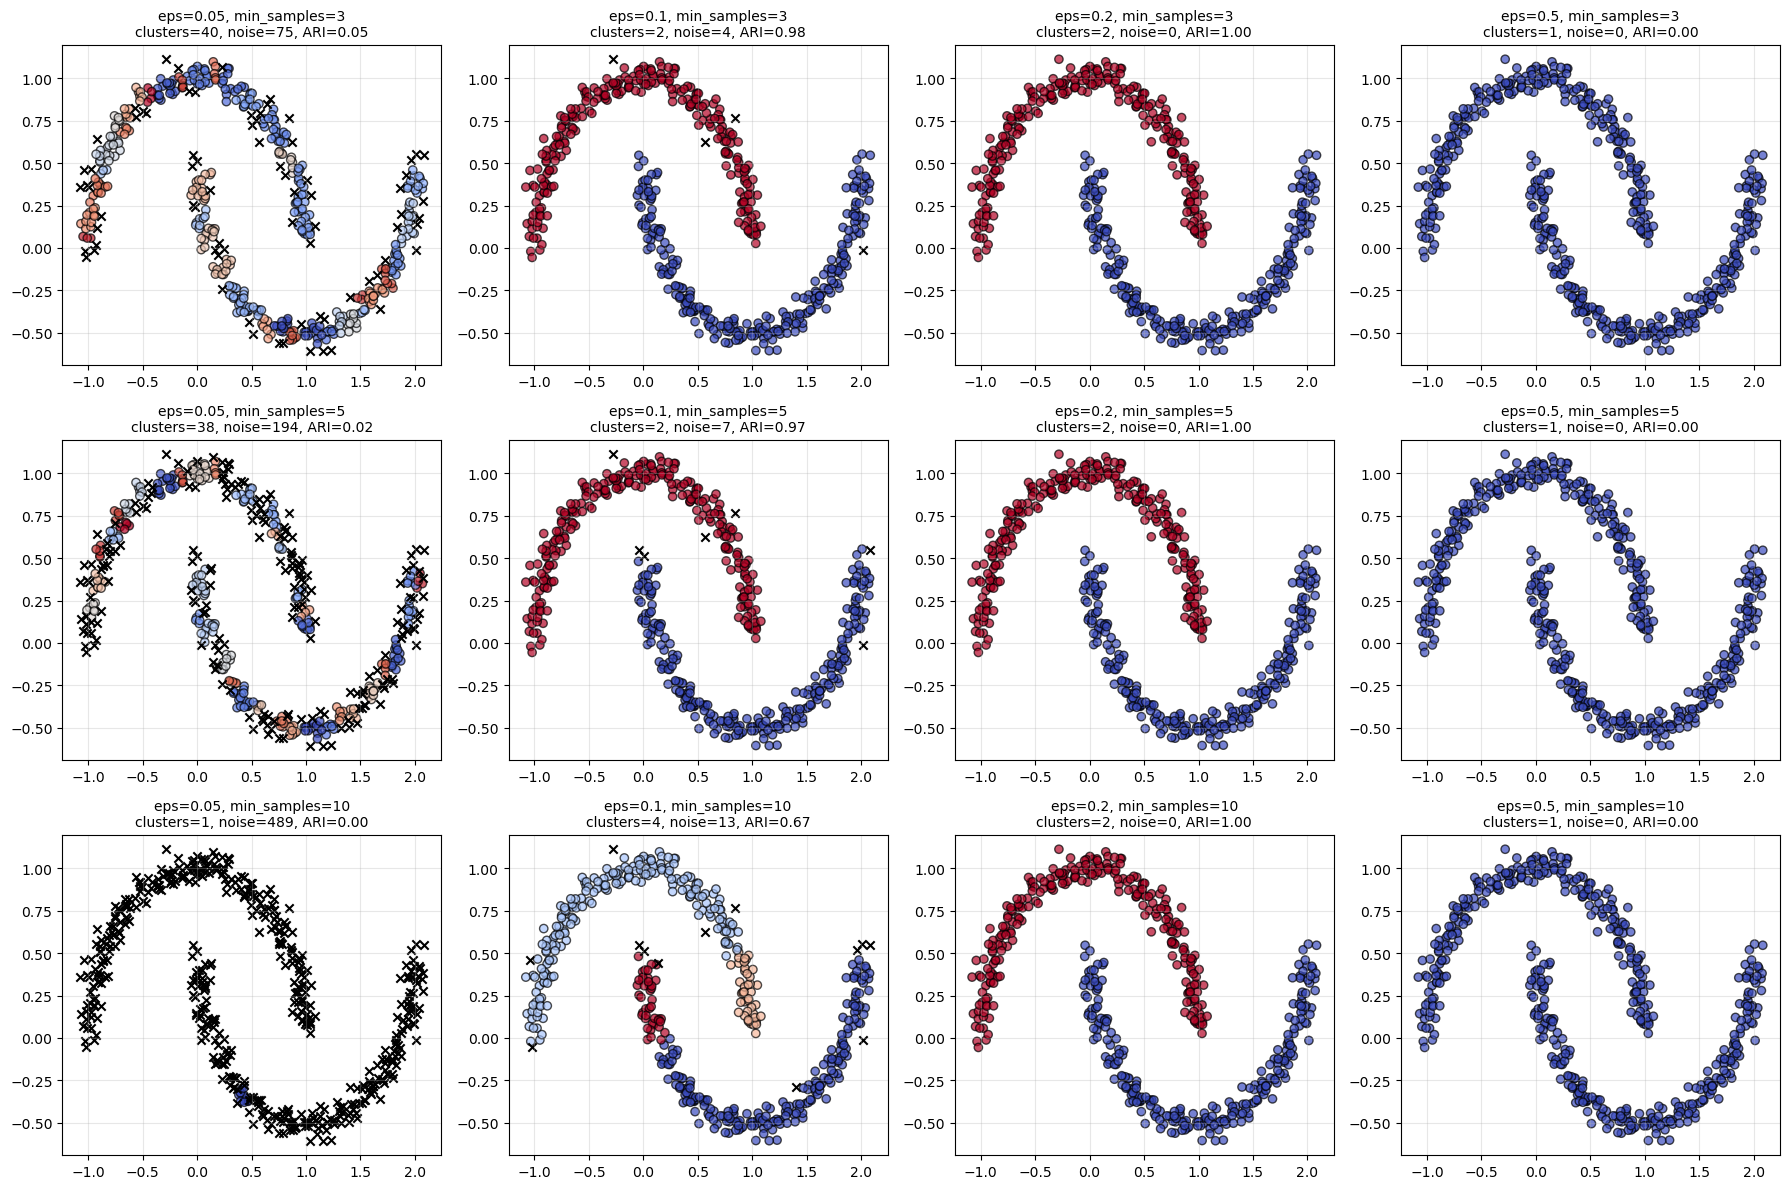

In [29]:
eps_values = [0.05, 0.1, 0.2, 0.5]
min_samples_values = [3, 5, 10]
fig, axes = plt.subplots(len(min_samples_values), len(eps_values), figsize=(18, 12))
results = []
for i, ms in enumerate(min_samples_values):
    for j, eps in enumerate(eps_values):
        db = DBSCAN(eps=eps, min_samples=ms)
        labels = db.fit_predict(X_moons)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = int(np.sum(labels == -1))
        ari = adjusted_rand_score(y_true, labels)
        results.append((eps, ms, n_clusters, n_noise, ari))
        ax = axes[i, j]
        noise_mask = labels == -1
        ax.scatter(X_moons[~noise_mask, 0], X_moons[~noise_mask, 1],
                   c=labels[~noise_mask], cmap="coolwarm", edgecolor="k", alpha=0.7)
        ax.scatter(X_moons[noise_mask, 0], X_moons[noise_mask, 1],
                   color="black", marker="x", label="Noise")
        ax.set_title(f"eps={eps}, min_samples={ms}\nclusters={n_clusters}, noise={n_noise}, ARI={ari:.2f}",
                     fontsize=10)
        ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [30]:
print(f"{'eps':>6} {'min_samples':>12} {'clusters':>9} {'noise':>6} {'ARI':>6}")
for eps, ms, nc, nn, ari in results:
    print(f"{eps:>6} {ms:>12} {nc:>9} {nn:>6} {ari:>6.2f}")

best = max(results, key=lambda r: r[4])
print(f"\nBest -> eps={best[0]}, min_samples={best[1]}, ARI={best[4]:.2f}")

   eps  min_samples  clusters  noise    ARI
  0.05            3        40     75   0.05
   0.1            3         2      4   0.98
   0.2            3         2      0   1.00
   0.5            3         1      0   0.00
  0.05            5        38    194   0.02
   0.1            5         2      7   0.97
   0.2            5         2      0   1.00
   0.5            5         1      0   0.00
  0.05           10         1    489   0.00
   0.1           10         4     13   0.67
   0.2           10         2      0   1.00
   0.5           10         1      0   0.00

Best -> eps=0.2, min_samples=3, ARI=1.00


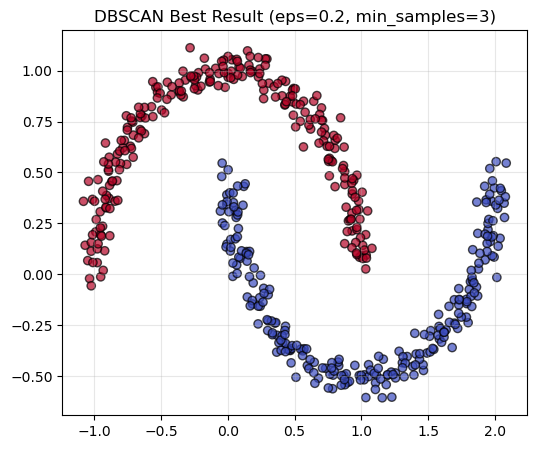

In [31]:
best_db = DBSCAN(eps=best[0], min_samples=best[1])
best_labels = best_db.fit_predict(X_moons)
plt.figure(figsize=(6, 5))
plt.scatter(X_moons[:, 0], X_moons[:, 1], c=best_labels, cmap="coolwarm", edgecolor="k", alpha=0.7)
plt.title(f"DBSCAN Best Result (eps={best[0]}, min_samples={best[1]})")
plt.grid(alpha=0.3)
plt.show()